# Reddit Post Volume vs. the S&P 500 (standalone)

Loads the pre-downloaded Reddit submissions from local Parquet files and plots weekly post volume per subreddit
against the S&P 500 from FRED. No Arctic Shift download is needed.

**Expected layout** (keep this notebook next to the `data/` folder, as in the zip):

```
proposal.ipynb
data/<YYYY-MM>/<subreddit>.parquet
```

Fetching the S&P 500 needs an internet connection (FRED, no API key required).

## 0. Setup

In [59]:
%pip install -q pandas pyarrow matplotlib duckdb pandas-datareader transformers torch

Note: you may need to restart the kernel to use updated packages.


In [60]:
from pathlib import Path

import duckdb
import pandas as pd
import pandas_datareader.data as web
import matplotlib.pyplot as plt
from transformers import pipeline
import torch

## 1. Configuration

In [61]:
DATA_DIR = Path("data")   # relative to this notebook

## 2. Load the data

Loading goes through DuckDB, so you can filter by date or subreddit before anything reaches pandas.

In [62]:
def load_reddit(subreddits=None, start=None, end=None, columns=None, data_dir=DATA_DIR, drop_removed=False):
    glob = str(Path(data_dir) / "*" / "*.parquet")
    where = ["1=1"]
    if subreddits:
        where.append("lower(subreddit) IN (" + ", ".join(f"'{s.lower()}'" for s in subreddits) + ")")
    if start:
        where.append(f"created_at >= TIMESTAMP '{start}'")
    if end:
        where.append(f"created_at < TIMESTAMP '{end}'")
    text = "trim(coalesce(title,'') || ' ' || CASE WHEN selftext IN ('[deleted]','[removed]') THEN '' ELSE coalesce(selftext,'') END)"
    removed = "(selftext IN ('[deleted]','[removed]') OR title IN ('[deleted]','[removed]','[deleted by user]'))"
    sel = "*" if columns is None else ", ".join(f'"{c}"' for c in columns)
    q = f'''
        SELECT {sel}, {text} AS text, {removed} AS is_removed
        FROM read_parquet('{glob}', union_by_name = true)
        WHERE {" AND ".join(where)}
        {"AND NOT " + removed if drop_removed else ""}
        ORDER BY created_at
    '''
    return duckdb.sql(q).df()

posts = load_reddit()
print(f"{len(posts):,} posts, {posts.created_at.min()} → {posts.created_at.max()}")
posts.head()

255,927 posts, 2010-01-01 00:10:07 → 2022-12-31 23:51:06


,id,subreddit,author,created_utc,created_at,title,selftext,score,num_comments,url,link_flair_text,over_18,text,is_removed
0,ake66,Economics,dieyoung,1262304607,2010-01-01 00:10:07,"For those who don't know, I present, The Mirac...",,4,3,http://en.wikipedia.org/wiki/Miracle_of_chile,None,False,"For those who don't know, I present, The Mirac...",False
1,ake7q,Economics,antediluvian,1262305024,2010-01-01 00:17:04,"Where we are, Where We're Heading: by K. Denni...",,1,0,http://market-ticker.org/archives/http://marke...,None,False,"Where we are, Where We're Heading: by K. Denni...",False
2,akebd,Economics,diggro,1262305895,2010-01-01 00:31:35,"George Carlin on paying high taxes: ""It made m...",,7,4,http://www.esquire.com/features/what-ive-learn...,None,False,"George Carlin on paying high taxes: ""It made m...",False
3,akelj,Economics,[deleted],1262308742,2010-01-01 01:19:02,The Media's Top 10 Worst Economic Myths of 2009,,0,0,http://businessandmedia.org/articles/2009/2009...,None,False,The Media's Top 10 Worst Economic Myths of 2009,False
4,akeug,Economics,[deleted],1262311426,2010-01-01 02:03:46,people and governments are now paying the pri...,[deleted],11,6,http://www.businessinsider.com/hsbc-chairman-s...,None,False,people and governments are now paying the pric...,True


In [63]:
drop_cols = ['id', 'author', 'is_removed', 'url', 'link_flair_text', 'over_18', 'is_removed', 'created_utc', 'selftext']
posts.drop(columns=drop_cols, inplace=True)


## 3. Post volume per subreddit vs the S&P 500

`sp_vs_posts` pulls the S&P 500 from FRED and plots it against weekly post volume for one subreddit over the
chosen period, with their correlation shown on the chart.

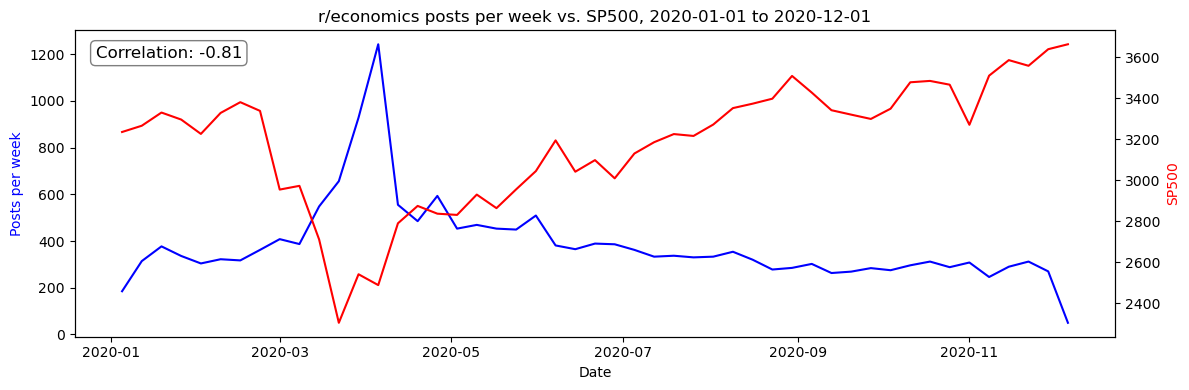

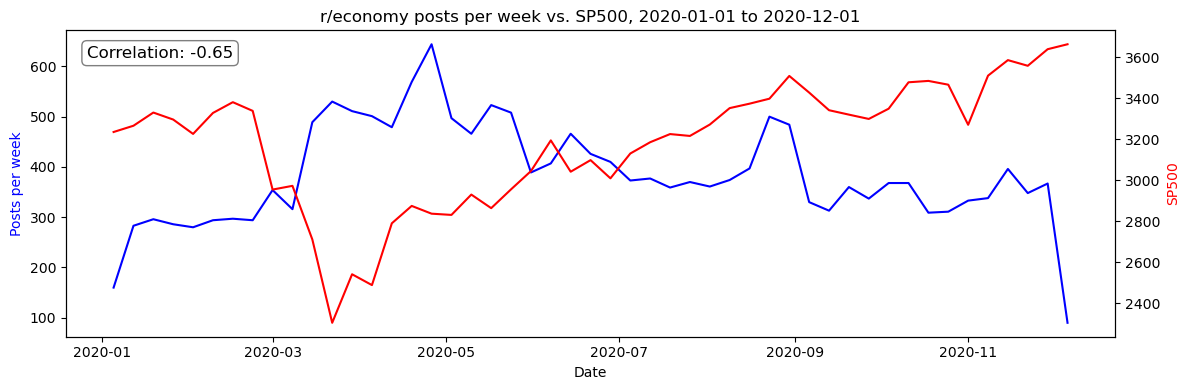

In [34]:
def sp_vs_posts(sub, start, end):
    df = load_reddit(subreddits=[sub], start=start, end=end)
    daily = df.set_index("created_at").resample("W").size().rename("posts")
    sp = web.DataReader('SP500', 'fred', start=start, end=end).resample("W").last()

    fig, ax1 = plt.subplots(figsize=(12, 4))
    ax1.plot(daily.index, daily.values, label="Posts per week", color='blue')
    ax1.set_ylabel("Posts per week", color="blue")
    ax1.set_xlabel("Date")

    ax2 = ax1.twinx()
    ax2.plot(sp.index, sp.values, label="SP500", color='red')
    ax2.set_ylabel("SP500", color="red")

    corr = daily.corr(sp["SP500"])

    ax1.set_title(f"r/{sub} posts per week vs. SP500, {start} to {end}")
    ax1.text(0.02, 0.95, f"Correlation: {corr:.2f}", transform=ax1.transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    fig.tight_layout()
    plt.show()


sp_vs_posts("economics", start="2020-01-01", end="2020-12-01")
sp_vs_posts("economy", start="2020-01-01", end="2020-12-01")

In [35]:
classifier = pipeline("text-classification", model="ProsusAI/finbert")
classifier("Stocks rallied and the British pound gained.")[0]
# [{'label': 'positive', 'score': 0.898...}]


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3754.75it/s]


{'label': 'positive', 'score': 0.8983616232872009}

In [70]:
# sample = posts.sample(5).apply(lambda row: classifier(row.text[:512]), axis=1)
sample = posts.sample(50).copy()
sample["classifier_result"] = sample["text"].apply(lambda text: classifier(text[:512])[0])
sample["label"] = sample["classifier_result"].apply(lambda x: x["label"])
sample["score"] = sample["classifier_result"].apply(lambda x: x["score"])
# sample[["text", "label", "score"]]
sample[["text", "label", "score"]].head(10)

,text,label,score
created_at,,,
2020-09-04 20:40:36,High volume but slow candle movement?,neutral,0.877177
2020-10-20 11:55:20,The Great Reset,neutral,0.796402
2017-03-02 23:39:27,German poverty rising - despite economic growt...,positive,0.615340
2020-11-19 02:46:38,Cathie Wood might lose control of ARK! https:/...,neutral,0.649254
2020-09-27 22:07:42,Where do you go to find investment ideas? Wher...,neutral,0.920490
2020-06-07 12:57:24,Top 10 Countries by Highest Real GDP (1990 - 2...,neutral,0.898675
2022-09-11 02:06:40,Basketball Hall of Fame enshrines its new Clas...,neutral,0.907598
2020-12-17 03:43:06,Is there any platform/website that compiles da...,neutral,0.948270
2022-08-29 14:05:20,Last member of Indigenous Brazilian tribe dies...,negative,0.565983


In [77]:
def sp_vs_posts_sentiment(sub, start, end):
    df = load_reddit(subreddits=[sub], start=start, end=end)
    # df["classifier_result"] = df["text"].apply(lambda text: classifier(text[:512])[0])
    # df["label"] = df["classifier_result"].apply(lambda x: x["label"])
    # df["score"] = df["classifier_result"].apply(lambda x: x["score"])

    weekly_samples = df.copy()
    weekly_samples["week"] = pd.to_datetime(weekly_samples["created_at"]).dt.to_period("W").dt.to_timestamp()

    weekly_samples = (
        weekly_samples.groupby("week")
        .apply(lambda g: g.sample(n=min(len(g), 100), random_state=42))
        .reset_index(drop=True)
    )

    weekly_samples["classifier_result"] = weekly_samples["text"].apply(lambda text: classifier(text[:512])[0])
    weekly_samples["label"] = weekly_samples["classifier_result"].apply(lambda x: x["label"])
    weekly_samples["score"] = weekly_samples["classifier_result"].apply(lambda x: x["score"])
    weekly_samples['n'] = weekly_samples.groupby('week')['label'].transform('count')
    
    weekly_samples['week_sentiment'] = weekly_samples['label'].map(
        {'positive': 1, 'neutral': 0, 'negative': -1}) * weekly_samples['score']
    return weekly_samples.groupby("week")["week_sentiment"].mean().rename("avg_sentiment").reset_index()

sentiment = sp_vs_posts_sentiment("economics", start="2020-01-01", end="2020-04-01")

/var/folders/z4/4j8f00gx7m1_gxdmyxzz2b080000gn/T/ipykernel_62444/2054756880.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), 100), random_state=42))


In [75]:
sp = web.DataReader('SP500', 'fred', start='2020-01-01', end='2020-04-01').resample("W").last()



Text(0.5, 0, 'Date')

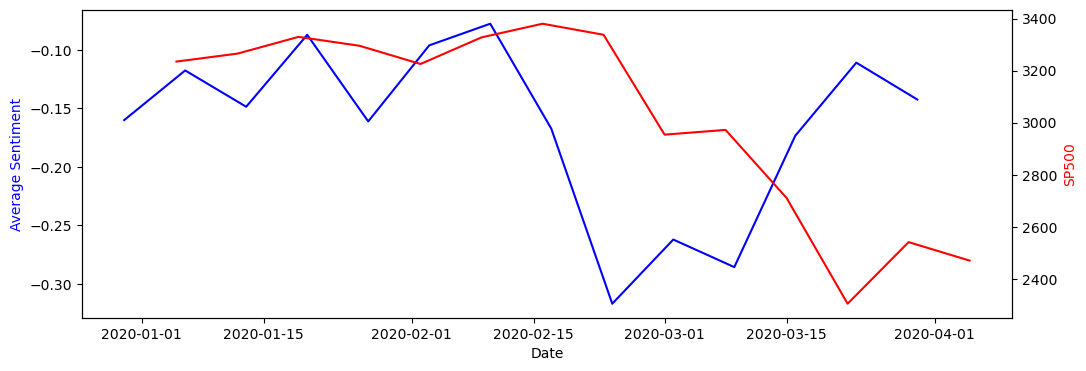

In [79]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(sentiment["week"], sentiment["avg_sentiment"], label="Average Sentiment", color='blue')
ax2 = ax1.twinx()
ax2.plot(sp.index, sp.values, label="SP500", color='red')
ax1.set_ylabel("Average Sentiment", color="blue")
ax2.set_ylabel("SP500", color="red")
ax1.set_xlabel("Date")